# Predicción de la generación fotovoltaica mediante regresión supervisada

Enfoque simplificado. Caso de aplicación: autoconsumo residencial.

## Objetivos

Conocer la generación fotovoltaica (FV) del día siguiente permite planificar el consumo de una vivienda con autoconsumo: desplazar cargas a las horas de mayor producción, gestionar una batería o reducir la energía importada de la red.

En esta práctica se entrena un modelo que estima la energía FV generada en cada hora a partir de variables meteorológicas y de calendario. Al terminar, el alumno debe ser capaz de:

- analizar y preparar una serie temporal de datos de generación y meteorología;
- entrenar y comparar varios modelos de regresión con `scikit-learn`;
- evaluar los resultados con métricas adecuadas y valorar si tienen sentido físico.

<img src="Figures/ml.png" alt="Flujo de trabajo de aprendizaje automático" width="800">

## 1. Datos de partida

### 1.1 Librerías y carga de datos

In [14]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

datos = pd.read_excel('data/regression_PVforecasting.xlsx')

### 1.2 Descripción de las variables

Cada fila corresponde a una hora. Las variables meteorológicas son valores medidos en esa hora.

| Columna | Magnitud | Unidad |
|---|---|---|
| `localhour` | Fecha y hora local | — |
| `pressure` | Presión atmosférica | hPa |
| `temperature` | Temperatura ambiente | °C |
| `humidity` | Humedad relativa | % |
| `windspeed` | Velocidad del viento | m/s |
| `rain` | Precipitación | mm |
| `radiation` | Irradiancia solar global horizontal | W/m² |
| `pvgen` | Energía FV generada en la hora (variable objetivo) | kWh |

Como el paso es de 1 h, la energía horaria en kWh coincide numéricamente con la potencia media de la hora en kW. Nótese que `radiation` es una irradiancia (potencia por unidad de superficie), no una irradiación (energía por unidad de superficie).

Diccionario de unidades, que se usará en las gráficas:

In [15]:
unidades = {'pressure': 'hPa', 'temperature': '°C', 'humidity': '%',
            'windspeed': 'm/s', 'rain': 'mm', 'radiation': 'W/m²', 'pvgen': 'kWh'}

### 1.3 Dimensiones y tipos de datos

Número de filas (registros horarios) y de columnas:

In [16]:
datos.shape

(10942, 8)

Primeras filas del conjunto:

In [17]:
datos.head()

,localhour,pressure,temperature,humidity,windspeed,rain,radiation,pvgen
0,2016-01-01 00:00:00,1027.2,10,70,3,0.0,0.0,0.0
1,2016-01-01 01:00:00,1027.1,9,69,3,0.0,0.0,0.0
2,2016-01-01 02:00:00,1027.9,9,68,3,0.0,0.0,0.0
3,2016-01-01 03:00:00,1027.9,9,68,3,0.0,0.0,0.0
4,2016-01-01 04:00:00,1028.2,8,70,3,0.0,0.0,0.0


Tipo de cada columna. Las columnas numéricas (`float64`, `int64`) se pueden usar directamente en un modelo; las de texto (`object`, o `str` en pandas 3) necesitan preprocesado.

In [18]:
datos.dtypes

localhour      datetime64[ns]
pressure              float64
temperature             int64
humidity                int64
windspeed               int64
rain                  float64
radiation             float64
pvgen                 float64
dtype: object

`localhour` se ha leído como texto. Se convierte a fecha y hora indicando el formato explícitamente (día/mes/año), para evitar que pandas confunda el día con el mes.

In [19]:
datos['localhour'] = pd.to_datetime(datos['localhour'], format='%d/%m/%Y %H:%M')

print('Inicio:', datos['localhour'].min())
print('Fin:   ', datos['localhour'].max())
datos.dtypes

Inicio: 2016-01-01 00:00:00
Fin:    2017-03-31 23:00:00


localhour      datetime64[ns]
pressure              float64
temperature             int64
humidity                int64
windspeed               int64
rain                  float64
radiation             float64
pvgen                 float64
dtype: object

### 1.4 Datos ausentes

Número de celdas vacías en cada columna:

In [20]:
datos.isna().sum()

localhour      0
pressure       0
temperature    0
humidity       0
windspeed      0
rain           0
radiation      2
pvgen          0
dtype: int64

Faltan unos pocos valores en las variables meteorológicas. La variable objetivo está completa. Los huecos se rellenan en el apartado 3.4, una vez separados los datos de entrenamiento y de prueba.

### 1.6 Resumen estadístico

In [23]:
datos.describe().round(2)

,localhour,pressure,temperature,humidity,windspeed,rain,radiation,pvgen
count,10942,10942.00,10942.00,10942.00,10942.00,10942.00,10940.00,10942.00
mean,2016-08-15 23:23:07.753609984,1016.09,20.64,70.72,1.70,0.04,179.85,1.59
min,2016-01-01 00:00:00,997.40,-6.00,15.00,0.00,0.00,0.00,0.00
25%,2016-04-24 00:15:00,1011.50,16.00,56.00,1.00,0.00,0.00,0.00
50%,2016-08-15 23:30:00,1015.00,21.00,74.00,2.00,0.00,1.00,0.00
75%,2016-12-07 22:45:00,1020.00,26.00,88.00,2.00,0.00,292.00,2.71
max,2017-03-31 23:00:00,1045.50,39.00,98.00,9.00,32.80,1101.00,9.54
std,NaN,6.77,7.64,19.89,1.26,0.64,273.26,2.40


## 2. Análisis exploratorio

### 2.1 Diagramas de caja

El diagrama de caja muestra la mediana, el rango intercuartílico (caja, que contiene el 50 % central de los valores) y los valores atípicos.

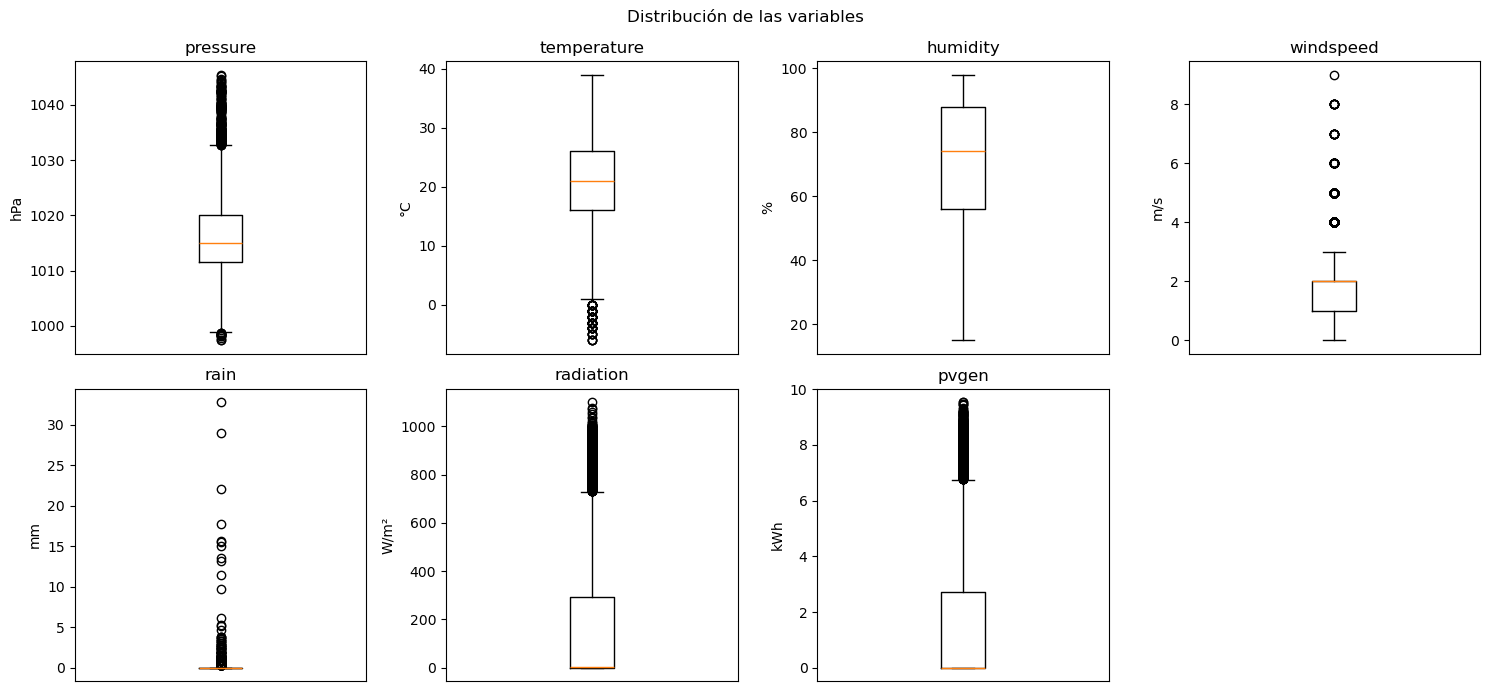

In [24]:
fig, ejes = plt.subplots(2, 4, figsize=(15, 7))
for eje, col in zip(ejes.flat, unidades):
    eje.boxplot(datos[col].dropna())
    eje.set_title(col)
    eje.set_ylabel(unidades[col])
    eje.set_xticks([])
ejes.flat[-1].axis('off')
fig.suptitle('Distribución de las variables')
plt.tight_layout()
plt.show()

Los valores atípicos de `rain` y `windspeed` son episodios reales, no errores de medida, así que no se eliminan. `radiation` y `pvgen` tienen una distribución muy asimétrica por la gran cantidad de ceros nocturnos.

### 2.2 Perfil diario medio de generación

Generación media de cada hora del día en cuatro meses representativos:

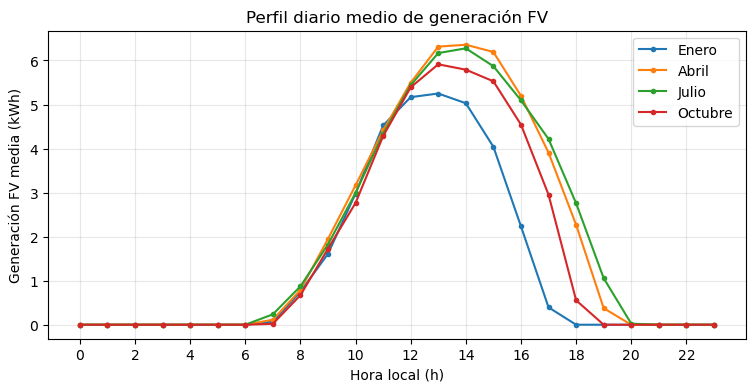

In [25]:
hora = datos['localhour'].dt.hour
mes = datos['localhour'].dt.month
perfil = datos.groupby([hora, mes])['pvgen'].mean().unstack()

fig, eje = plt.subplots(figsize=(9, 4))
for m, nombre in [(1, 'Enero'), (4, 'Abril'), (7, 'Julio'), (10, 'Octubre')]:
    eje.plot(perfil.index, perfil[m], marker='o', ms=3, label=nombre)
eje.set_xlabel('Hora local (h)')
eje.set_ylabel('Generación FV media (kWh)')
eje.set_title('Perfil diario medio de generación FV')
eje.set_xticks(range(0, 24, 2))
eje.grid(alpha=0.3)
eje.legend()
plt.show()

La generación es nula de noche y el máximo se produce hacia las 13–14 h, desplazado respecto al mediodía solar por el horario de verano y por la longitud del emplazamiento dentro de su huso horario. En verano los días son más largos y la energía diaria es mayor. La hora y el mes, por tanto, aportan información útil al modelo.

### 2.3 Relación entre irradiancia y generación

La potencia de un generador FV es aproximadamente proporcional a la irradiancia que recibe. Si se divide la energía horaria entre la irradiancia y se escala a 1000 W/m², se obtiene una estimación de la potencia de la instalación en condiciones próximas a las estándar de medida (STC). Se calcula con las horas de irradiancia alta, donde la relación es más estable.

Potencia equivalente a 1000 W/m²: 8.1 kW


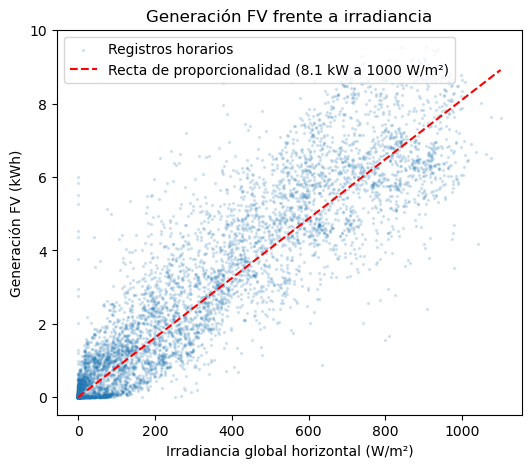

In [26]:
alta = datos['radiation'] > 600
p_1000 = (datos.loc[alta, 'pvgen'] / datos.loc[alta, 'radiation'] * 1000).median()
print(f'Potencia equivalente a 1000 W/m²: {p_1000:.1f} kW')

g = np.linspace(0, 1100, 2)
fig, eje = plt.subplots(figsize=(6, 5))
eje.scatter(datos['radiation'], datos['pvgen'], s=2, alpha=0.15, label='Registros horarios')
eje.plot(g, p_1000 * g / 1000, 'r--', label=f'Recta de proporcionalidad ({p_1000:.1f} kW a 1000 W/m²)')
eje.set_xlabel('Irradiancia global horizontal (W/m²)')
eje.set_ylabel('Generación FV (kWh)')
eje.set_title('Generación FV frente a irradiancia')
eje.legend()
plt.show()

La relación es casi lineal. La dispersión se debe a que la irradiancia se mide en el plano horizontal y no en el de los módulos, y a otros efectos que no recoge esta variable: temperatura de célula, ángulo de incidencia, sombras o suciedad. Por eso la estimación de unos 7–8 kW queda por debajo del máximo observado. Los pocos puntos con irradiancia nula y generación alta son probablemente errores de registro.

### 2.4 Matriz de correlación

El coeficiente de Pearson mide el grado de relación lineal entre dos variables, entre −1 y 1. Sirve para dos cosas:

- identificar las variables más relacionadas con la variable objetivo;
- detectar variables de entrada muy correlacionadas entre sí (multicolinealidad), que aportan información redundante y pueden hacer inestables los modelos lineales.

Para relaciones monótonas no lineales es preferible el coeficiente de Spearman (`method='spearman'`).

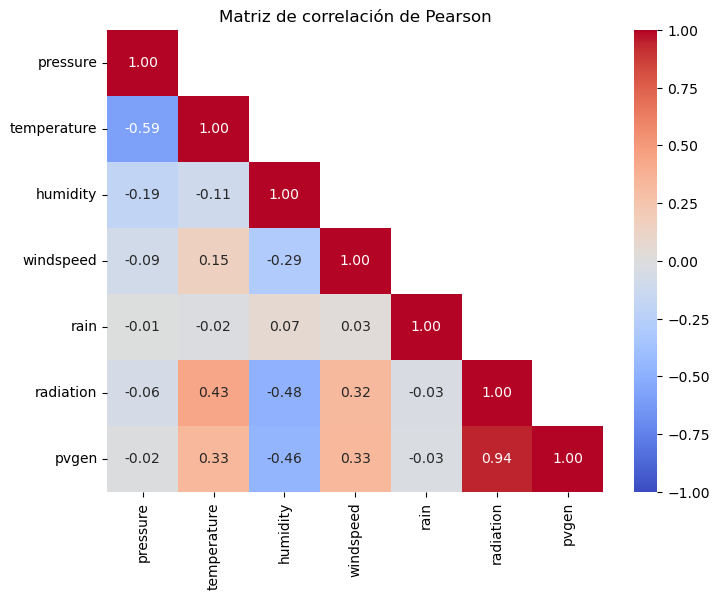

In [27]:
corr = datos.drop(columns='localhour').corr(method='pearson')
mascara = np.triu(np.ones_like(corr, dtype=bool), k=1)   # oculta el triángulo superior

plt.figure(figsize=(8, 6))
sns.heatmap(corr, mask=mascara, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Matriz de correlación de Pearson')
plt.show()

La irradiancia es, con diferencia, la variable más correlacionada con la generación (0,94). La humedad tiene una correlación negativa apreciable, porque está asociada a la nubosidad. La presión y la lluvia apenas tienen relación lineal con `pvgen`.

## 3. Preparación de los datos

### 3.1 Variables de calendario

Se extraen la hora y el mes de `localhour`. La columna de fecha se guarda aparte para las gráficas y se retira del conjunto de datos.

In [28]:
datos['hora'] = datos['localhour'].dt.hour
datos['mes'] = datos['localhour'].dt.month
fechas = datos.pop('localhour')
datos.head()

,pressure,temperature,humidity,windspeed,rain,radiation,pvgen,hora,mes
0,1027.2,10,70,3,0.0,0.0,0.0,0,1
1,1027.1,9,69,3,0.0,0.0,0.0,1,1
2,1027.9,9,68,3,0.0,0.0,0.0,2,1
3,1027.9,9,68,3,0.0,0.0,0.0,3,1
4,1028.2,8,70,3,0.0,0.0,0.0,4,1


La hora y el mes se tratan como variables numéricas. Esto tiene un inconveniente: las 23 h y las 0 h son consecutivas, pero numéricamente están muy alejadas (lo mismo ocurre con diciembre y enero). Se plantea una alternativa en el ejercicio 2.

### 3.2 Variables de entrada y variable objetivo

Se separan las variables de entrada `X` de la variable objetivo `y` (`pvgen`).

In [29]:
X = datos.drop(columns='pvgen')
y = datos['pvgen']
X.columns.tolist()

['pressure',
 'temperature',
 'humidity',
 'windspeed',
 'rain',
 'radiation',
 'hora',
 'mes']

Observación: aquí la irradiancia de entrada es la medida. Para predecir el día siguiente en una instalación real habría que usar la irradiancia prevista por un servicio meteorológico, que tiene su propio error. Los resultados de esta práctica son, por tanto, una cota optimista de lo que se obtendría en explotación.

### 3.3 División en entrenamiento y prueba

Se reserva el 20 % final de la serie para la prueba. Los datos no se barajan (`shuffle=False`): en una serie temporal, mezclar haría que el modelo se entrenase con horas contiguas a las de prueba, y las métricas saldrían optimistas. En este enfoque simplificado no se usa un conjunto de validación.

In [30]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, shuffle=False)

for nombre, serie in [('Entrenamiento', y_train), ('Prueba', y_test)]:
    f = fechas.loc[serie.index]
    print(f'{nombre:14s} {f.min()} → {f.max()}  ({len(serie)} h)')

Entrenamiento  2016-01-01 00:00:00 → 2016-12-30 17:00:00  (8753 h)
Prueba         2016-12-30 18:00:00 → 2017-03-31 23:00:00  (2189 h)


### 3.4 Imputación de datos ausentes

Los huecos de las variables de entrada se rellenan por interpolación lineal entre las horas vecinas. Se hace por separado en cada conjunto, para no usar información del periodo de prueba al preparar el de entrenamiento.

In [31]:
X_train = X_train.interpolate(method='linear', limit_direction='both')
X_test = X_test.interpolate(method='linear', limit_direction='both')

print('Ausentes en entrenamiento:', X_train.isna().sum().sum())
print('Ausentes en prueba:       ', X_test.isna().sum().sum())

Ausentes en entrenamiento: 0
Ausentes en prueba:        0


### 3.5 Escalado

Las variables tienen rangos muy distintos (irradiancia de 0 a 1100 W/m², viento de 0 a 9 m/s). Los modelos basados en distancias (KNN) y las redes neuronales necesitan que todas estén en una escala comparable; los árboles de decisión no. Los escaladores más habituales son:

- `StandardScaler`: media 0 y desviación típica 1.
- `MinMaxScaler`: lleva cada variable al intervalo [0, 1]. Es sensible a los valores atípicos.
- `RobustScaler`: usa la mediana y el rango intercuartílico; es adecuado cuando hay muchos valores atípicos.

Se usa `MinMaxScaler`. El escalador se ajusta solo con los datos de entrenamiento y después se aplica, sin reajustar, a los de prueba.

In [32]:
from sklearn.preprocessing import MinMaxScaler

escalador = MinMaxScaler()
X_train_esc = escalador.fit_transform(X_train)   # ajuste + transformación
X_test_esc = escalador.transform(X_test)         # solo transformación

pd.DataFrame(X_test_esc, columns=X.columns).describe().loc[['min', 'max']].round(2)

,pressure,temperature,humidity,windspeed,rain,radiation,hora,mes
min,-0.02,-0.05,-0.02,0.00,0.00,0.00,0.0,0.0
max,1.06,0.84,1.00,0.89,0.48,0.82,1.0,1.0


En el conjunto de prueba algunos valores quedan ligeramente fuera de [0, 1]. Es normal: el escalador solo conoce el rango de los datos de entrenamiento.

## 4. Modelos de regresión


### 4.1 Entrenamiento

Se comparan tres modelos de `scikit-learn`:

- Random Forest: conjunto de árboles de decisión entrenados con subconjuntos aleatorios de los datos; la predicción es la media de todos los árboles.
- KNN (*k-nearest neighbours*): predice la media de la variable objetivo en los *k* registros de entrenamiento más próximos.
- MLP (*multilayer perceptron*): red neuronal con una capa oculta de 100 neuronas.

Todos siguen el mismo procedimiento: `fit()` ajusta los parámetros del modelo con los datos de entrenamiento y `predict()` calcula la salida para datos nuevos. Se fija `random_state` para que los resultados sean reproducibles.

In [34]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.neural_network import MLPRegressor

modelos = {
    'Random Forest': RandomForestRegressor(random_state=0, n_jobs=-1),
    'KNN': KNeighborsRegressor(n_neighbors=5),
    'MLP': MLPRegressor(max_iter=500, random_state=0),
}

for nombre, modelo in modelos.items():
    modelo.fit(X_train_esc, y_train)
    pred[nombre] = modelo.predict(X_test_esc)

La generación FV no puede ser negativa, pero un modelo de regresión no lo sabe. Se cuentan las predicciones negativas y se recortan a cero:

In [35]:
for nombre, p in pred.items():
    print(f'{nombre:14s} {(p < 0).sum():5d} predicciones negativas')
    pred[nombre] = np.clip(p, 0, None)

Persistencia       0 predicciones negativas
Random Forest      0 predicciones negativas
KNN                0 predicciones negativas
MLP              832 predicciones negativas


### 4.3 Métricas de evaluación

Siendo $y_i$ el valor real, $\hat{y}_i$ el predicho y $n$ el número de horas:

$$\mathrm{MAE} = \frac{1}{n}\sum_{i=1}^{n}\left|y_i-\hat{y}_i\right| \qquad
\mathrm{RMSE} = \sqrt{\frac{1}{n}\sum_{i=1}^{n}\left(y_i-\hat{y}_i\right)^2} \qquad
R^2 = 1-\frac{\sum_i \left(y_i-\hat{y}_i\right)^2}{\sum_i \left(y_i-\bar{y}\right)^2}$$

El MAE y el RMSE se expresan en las unidades de la variable (kWh); el RMSE penaliza más los errores grandes. $R^2$ es adimensional: vale 1 si la predicción es perfecta y 0 si el modelo no mejora la media.

Se añade además el error en la energía total del periodo de prueba, $\left(\sum\hat{y}_i - \sum y_i\right)/\sum y_i$. Un modelo puede tener un RMSE bajo y, aun así, sobrestimar o subestimar de forma sistemática la energía producida, que es lo que importa para el balance de la vivienda.

La lista completa de métricas está en la [documentación de scikit-learn](https://scikit-learn.org/stable/modules/model_evaluation.html).

In [36]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

def evaluar(y_real, y_pred):
    return {
        'MAE (kWh)': mean_absolute_error(y_real, y_pred),
        'RMSE (kWh)': np.sqrt(mean_squared_error(y_real, y_pred)),
        'R²': r2_score(y_real, y_pred),
        'Error energía (%)': 100 * (y_pred.sum() - y_real.sum()) / y_real.sum(),
    }

resultados = pd.DataFrame({n: evaluar(y_test, p) for n, p in pred.items()}).T
resultados.round(3)

,MAE (kWh),RMSE (kWh),R²,Error energía (%)
Persistencia,0.476,1.133,0.706,-1.616
Random Forest,0.381,0.733,0.877,24.292
KNN,0.441,0.810,0.850,27.087
MLP,0.379,0.690,0.891,23.044


La persistencia acierta casi exactamente la energía total, ya que es la misma serie desplazada un día, pero hora a hora comete errores grandes. El Random Forest y el KNN sobrestiman la energía del periodo de prueba en torno a un 4–5 %.

### 4.4 Comparación gráfica



Gráfica interactiva de todo el periodo de prueba, que permite ampliar cualquier intervalo. Requiere la librería Plotly (`pip install plotly`).

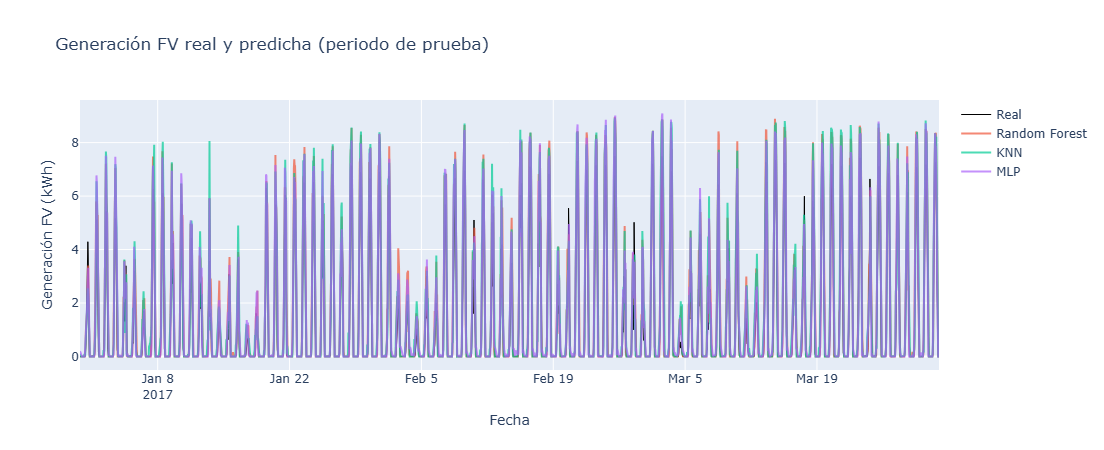

In [44]:
import plotly.graph_objects as go

fig = go.Figure()
fig.add_trace(go.Scatter(x=fechas_test, y=y_test, mode='lines', name='Real',
                         line=dict(color='black', width=1)))
for nombre in modelos:
    fig.add_trace(go.Scatter(x=fechas_test, y=pred[nombre], mode='lines', name=nombre, opacity=0.7))
fig.update_layout(title='Generación FV real y predicha (periodo de prueba)',
                  xaxis_title='Fecha', yaxis_title='Generación FV (kWh)',
                  width=1000, height=450)
fig.show()

Diagrama de dispersión de la predicción frente al valor real para el Random Forest. Cuanto más cerca de la diagonal estén los puntos, mejor es la predicción.

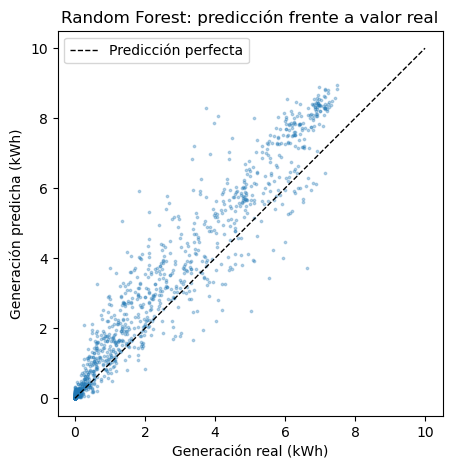

In [45]:
fig, eje = plt.subplots(figsize=(5, 5))
eje.scatter(y_test, pred['Random Forest'], s=3, alpha=0.3)
eje.plot([0, 10], [0, 10], 'k--', lw=1, label='Predicción perfecta')
eje.set_xlabel('Generación real (kWh)')
eje.set_ylabel('Generación predicha (kWh)')
eje.set_title('Random Forest: predicción frente a valor real')
eje.set_aspect('equal')
eje.legend()
plt.show()

## 5. Interpretación del Random Forest

### 5.1 Importancia de las variables

El Random Forest permite cuantificar cuánto contribuye cada variable a reducir el error en los árboles:

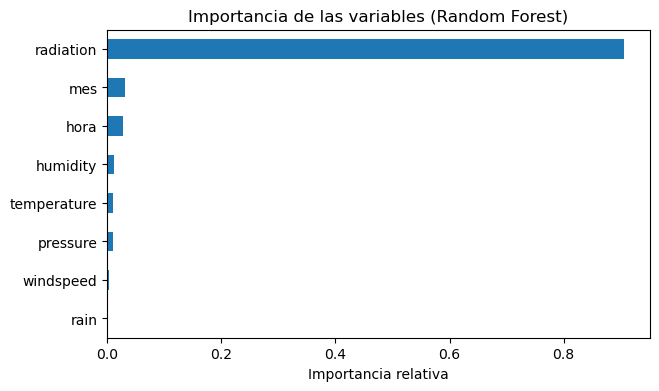

In [46]:
rf = modelos['Random Forest']
importancia = pd.Series(rf.feature_importances_, index=X.columns).sort_values()

importancia.plot.barh(figsize=(7, 4))
plt.xlabel('Importancia relativa')
plt.title('Importancia de las variables (Random Forest)')
plt.show()

### 5.2 Estructura de un árbol

Primeros niveles de uno de los árboles del bosque. En cada nodo aparecen la condición de división, el error cuadrático medio, el número de muestras y el valor medio de `pvgen` (kWh). Los umbrales están en unidades escaladas, entre 0 y 1, porque el modelo se ha entrenado con los datos escalados.

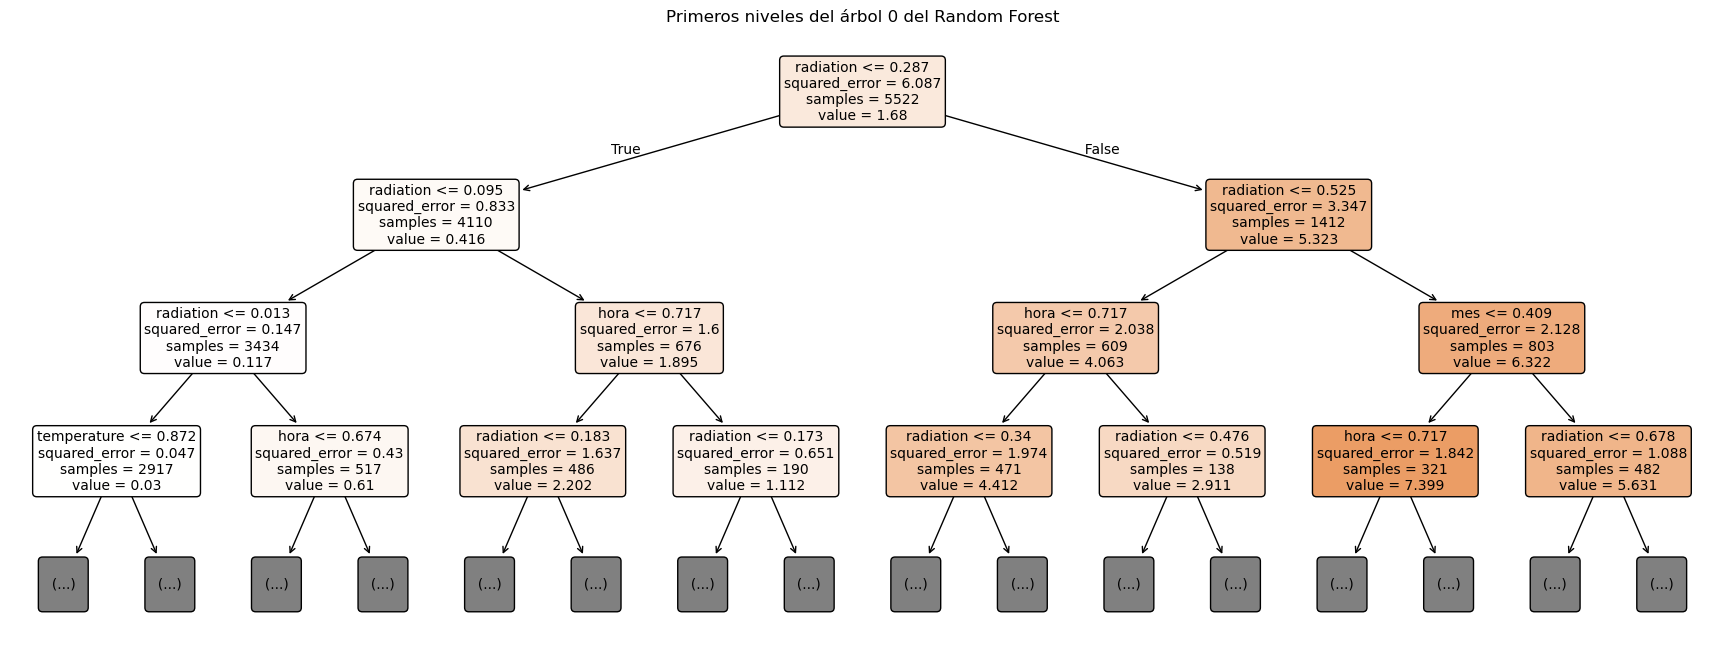

In [47]:
from sklearn import tree

plt.figure(figsize=(22, 8))
tree.plot_tree(rf.estimators_[0], max_depth=3, feature_names=list(X.columns),
               filled=True, rounded=True, fontsize=10)
plt.title('Primeros niveles del árbol 0 del Random Forest')
plt.show()

## 6. Ejercicios propuestos

1. Elimina de `X` las variables con menor correlación con `pvgen` y vuelve a entrenar los modelos. ¿Empeoran las métricas?
2. Prueba distintos valores de `n_neighbors` en el KNN (por ejemplo, de 1 a 30) y representa el RMSE en función de *k*. Prueba con diferentes valores de `n_estimators` en Random Forest.
3. Añade 5 features al modelo. 